<a href="https://colab.research.google.com/github/fadlifernando10/Kelompok2-Supermarket_Saless/blob/main/Kelompok2_Supermarket_Sales_Dataset.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd

path = '/content/drive/MyDrive/Kelompok 2 ML/SuperMarket Analysis.csv'
df = pd.read_csv(path)
df.head()


,Invoice ID,Branch,City,Customer type,Gender,Product line,Unit price,Quantity,Tax 5%,Sales,Date,Time,Payment,cogs,gross margin percentage,gross income,Rating
0,750-67-8428,Alex,Yangon,Member,Female,Health and beauty,74.69,7,26.1415,548.9715,1/5/2019,1:08:00 PM,Ewallet,522.83,4.761905,26.1415,9.1
1,226-31-3081,Giza,Naypyitaw,Normal,Female,Electronic accessories,15.28,5,3.8200,80.2200,3/8/2019,10:29:00 AM,Cash,76.40,4.761905,3.8200,9.6
2,631-41-3108,Alex,Yangon,Normal,Female,Home and lifestyle,46.33,7,16.2155,340.5255,3/3/2019,1:23:00 PM,Credit card,324.31,4.761905,16.2155,7.4
3,123-19-1176,Alex,Yangon,Member,Female,Health and beauty,58.22,8,23.2880,489.0480,1/27/2019,8:33:00 PM,Ewallet,465.76,4.761905,23.2880,8.4
4,373-73-7910,Alex,Yangon,Member,Female,Sports and travel,86.31,7,30.2085,634.3785,2/8/2019,10:37:00 AM,Ewallet,604.17,4.761905,30.2085,5.3


**Langkah 1**

In [2]:
from numpy._core.fromnumeric import shape
import pandas as pd

# Memuat dataset dan mengantisipasi penanda data hilang yang bukan sel kosong
df = pd.read_csv(path,
    sep=",",
    encoding="utf-8",
    na_values=["?", "---", "", "unknown", "Unknown", "NA", "n/a", "N/A"],
    skipinitialspace=True
)

print("Ukuran dataset (baris, kolom):", df.shape)

Ukuran dataset (baris, kolom): (1000, 17)


In [3]:
duplicate_count = df.duplicated().sum()
print(f"Jumlah baris duplikat pada dataset: {duplicate_count}")

Jumlah baris duplikat pada dataset: 0


**Langkah 2**

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 17 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Invoice ID               1000 non-null   object 
 1   Branch                   1000 non-null   object 
 2   City                     1000 non-null   object 
 3   Customer type            1000 non-null   object 
 4   Gender                   1000 non-null   object 
 5   Product line             1000 non-null   object 
 6   Unit price               1000 non-null   float64
 7   Quantity                 1000 non-null   int64  
 8   Tax 5%                   1000 non-null   float64
 9   Sales                    1000 non-null   float64
 10  Date                     1000 non-null   object 
 11  Time                     1000 non-null   object 
 12  Payment                  1000 non-null   object 
 13  cogs                     1000 non-null   float64
 14  gross margin percentage  

In [5]:
df.head(10)

,Invoice ID,Branch,City,Customer type,Gender,Product line,Unit price,Quantity,Tax 5%,Sales,Date,Time,Payment,cogs,gross margin percentage,gross income,Rating
0,750-67-8428,Alex,Yangon,Member,Female,Health and beauty,74.69,7,26.1415,548.9715,1/5/2019,1:08:00 PM,Ewallet,522.83,4.761905,26.1415,9.1
1,226-31-3081,Giza,Naypyitaw,Normal,Female,Electronic accessories,15.28,5,3.8200,80.2200,3/8/2019,10:29:00 AM,Cash,76.40,4.761905,3.8200,9.6
2,631-41-3108,Alex,Yangon,Normal,Female,Home and lifestyle,46.33,7,16.2155,340.5255,3/3/2019,1:23:00 PM,Credit card,324.31,4.761905,16.2155,7.4
3,123-19-1176,Alex,Yangon,Member,Female,Health and beauty,58.22,8,23.2880,489.0480,1/27/2019,8:33:00 PM,Ewallet,465.76,4.761905,23.2880,8.4
4,373-73-7910,Alex,Yangon,Member,Female,Sports and travel,86.31,7,30.2085,634.3785,2/8/2019,10:37:00 AM,Ewallet,604.17,4.761905,30.2085,5.3
5,699-14-3026,Giza,Naypyitaw,Member,Female,Electronic accessories,85.39,7,29.8865,627.6165,3/25/2019,6:30:00 PM,Ewallet,597.73,4.761905,29.8865,4.1
6,355-53-5943,Alex,Yangon,Member,Female,Electronic accessories,68.84,6,20.6520,433.6920,2/25/2019,2:36:00 PM,Ewallet,413.04,4.761905,20.6520,5.8
7,315-22-5665,Giza,Naypyitaw,Member,Female,Home and lifestyle,73.56,10,36.7800,772.3800,2/24/2019,11:38:00 AM,Ewallet,735.60,4.761905,36.7800,8.0
8,665-32-9167,Alex,Yangon,Member,Female,Health and beauty,36.26,2,3.6260,76.1460,1/10/2019,5:15:00 PM,Credit card,72.52,4.761905,3.6260,7.2
9,692-92-5582,Cairo,Mandalay,Member,Female,Food and beverages,54.84,3,8.2260,172.7460,2/20/2019,1:27:00 PM,Credit card,164.52,4.761905,8.2260,5.9


In [6]:
df.describe()

,Unit price,Quantity,Tax 5%,Sales,cogs,gross margin percentage,gross income,Rating
count,1000.000000,1000.000000,1000.000000,1000.000000,1000.00000,1.000000e+03,1000.000000,1000.00000
mean,55.672130,5.510000,15.379369,322.966749,307.58738,4.761905e+00,15.379369,6.97270
std,26.494628,2.923431,11.708825,245.885335,234.17651,6.131498e-14,11.708825,1.71858
min,10.080000,1.000000,0.508500,10.678500,10.17000,4.761905e+00,0.508500,4.00000
25%,32.875000,3.000000,5.924875,124.422375,118.49750,4.761905e+00,5.924875,5.50000
50%,55.230000,5.000000,12.088000,253.848000,241.76000,4.761905e+00,12.088000,7.00000
75%,77.935000,8.000000,22.445250,471.350250,448.90500,4.761905e+00,22.445250,8.50000
max,99.960000,10.000000,49.650000,1042.650000,993.00000,4.761905e+00,49.650000,10.00000


In [7]:
df.describe(include='object')

,Invoice ID,Branch,City,Customer type,Gender,Product line,Date,Time,Payment
count,1000,1000,1000,1000,1000,1000,1000,1000,1000
unique,1000,3,3,2,2,6,89,506,3
top,750-67-8428,Alex,Yangon,Member,Female,Fashion accessories,2/7/2019,7:48:00 PM,Ewallet
freq,1,340,340,565,571,178,20,7,345


**Kesimpulan Langkah 2**
1. Unit Analisis: Satu baris data pada dataset ini mewakili struk penjualan tunggal pada salah satu cabang supermarket. Karena setiap baris memiliki Invoice ID yang unik (1.000 unik dari 1.000 baris), maka tidak diperlukan penggabungan tabel (merge) maupun agregasi (groupby) data sebelum pemodelan
2. ketidak sesuaian tipe data pada kolom Date dan kolom Time, dimana pada dataset menunjukan tipe data object atau terbaca sebagai text. seharusnya menggunakan tipe data datetime atau waktu. kemudian kolom kolom yang masih bertipe data object harus di ubah menjadi angka untuk penghitungan model regresi linear.

**Langkah 3**

1. Nilai hilang

In [8]:
hilang = pd.DataFrame({
 'jumlah': df.isna().sum(),
 'persen': (df.isna().mean() * 100).round(2)
}).sort_values('persen', ascending=False)
print(hilang[hilang['jumlah'] > 0])


Empty DataFrame
Columns: [jumlah, persen]
Index: []


2. data hilang tersamar

In [9]:
# untuk kolom yang secara logika tidak mungkin nol
for k in ['Unit price', 'Quantity']:
 print(k, '->', (df[k] == 0).sum(), 'baris bernilai nol')



Unit price -> 0 baris bernilai nol
Quantity -> 0 baris bernilai nol


In [10]:
# untuk kolom kategori: lihat seluruh nilai uniknya
for k in df.select_dtypes('object').columns:
 print(k, df[k].unique()[:12])

Invoice ID ['750-67-8428' '226-31-3081' '631-41-3108' '123-19-1176' '373-73-7910'
 '699-14-3026' '355-53-5943' '315-22-5665' '665-32-9167' '692-92-5582'
 '351-62-0822' '529-56-3974']
Branch ['Alex' 'Giza' 'Cairo']
City ['Yangon' 'Naypyitaw' 'Mandalay']
Customer type ['Member' 'Normal']
Gender ['Female' 'Male']
Product line ['Health and beauty' 'Electronic accessories' 'Home and lifestyle'
 'Sports and travel' 'Food and beverages' 'Fashion accessories']
Date ['1/5/2019' '3/8/2019' '3/3/2019' '1/27/2019' '2/8/2019' '3/25/2019'
 '2/25/2019' '2/24/2019' '1/10/2019' '2/20/2019' '2/6/2019' '3/9/2019']
Time ['1:08:00 PM' '10:29:00 AM' '1:23:00 PM' '8:33:00 PM' '10:37:00 AM'
 '6:30:00 PM' '2:36:00 PM' '11:38:00 AM' '5:15:00 PM' '1:27:00 PM'
 '6:07:00 PM' '5:03:00 PM']
Payment ['Ewallet' 'Cash' 'Credit card']


3. Duplikasi

In [11]:
print('baris identik seluruhnya :', df.duplicated().sum())
print('identifier berulang :', df['Invoice ID'].duplicated().sum()) # jika ada kolom id

baris identik seluruhnya : 0
identifier berulang : 0


In [12]:
missing_values = df.isnull().sum()
print("Jumlah Missing Value per Kolom:")
print(missing_values)

print(f"\nTotal keseluruhan missing value: {missing_values.sum()}")

Jumlah Missing Value per Kolom:
Invoice ID                 0
Branch                     0
City                       0
Customer type              0
Gender                     0
Product line               0
Unit price                 0
Quantity                   0
Tax 5%                     0
Sales                      0
Date                       0
Time                       0
Payment                    0
cogs                       0
gross margin percentage    0
gross income               0
Rating                     0
dtype: int64

Total keseluruhan missing value: 0


4. kolom konstant dan identifier

In [13]:
n = df.nunique()
print('kolom konstan :', list(n[n <= 1].index))
print('hampir unik per baris:', list(n[n > 0.9 * len(df)].index))

kolom konstan : ['gross margin percentage']
hampir unik per baris: ['Invoice ID', 'Unit price', 'Tax 5%', 'Sales', 'cogs', 'gross income']


5. Konsistensi label kategori

In [14]:
print("\n=== 3f. KONSISTENSI LABEL KATEGORI ===")
for col in ['Branch', 'City', 'Customer type', 'Gender', 'Payment']:
    print(f"{col}: {df[col].unique()}")


=== 3f. KONSISTENSI LABEL KATEGORI ===
Branch: ['Alex' 'Giza' 'Cairo']
City: ['Yangon' 'Naypyitaw' 'Mandalay']
Customer type: ['Member' 'Normal']
Gender: ['Female' 'Male']
Payment: ['Ewallet' 'Cash' 'Credit card']


Langkah 4 - Pahami variabel target model regresi linear

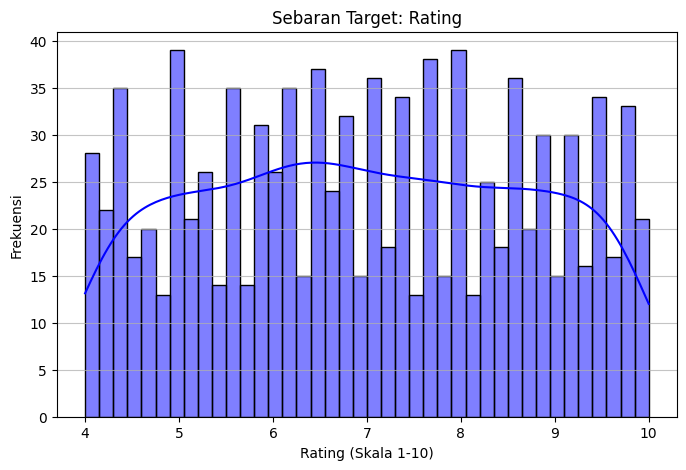

In [15]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Membuat histogram untuk melihat sebaran target Rating
plt.figure(figsize=(8, 5))
sns.histplot(df['Rating'], bins=40, kde=True, color='blue')
plt.title('Sebaran Target: Rating')
plt.xlabel('Rating (Skala 1-10)')
plt.ylabel('Frekuensi')
plt.grid(axis='y', alpha=0.75)
plt.show()



In [16]:
# 2. Menghitung nilai korelasi numerik terhadap target Rating
target = 'Rating'
num_cols = df.select_dtypes(include=['float64', 'int64'])
print("=== KORELASI FITUR NUMERIK TERHADAP RATING ===")
print(num_cols.corr()[target].sort_values(ascending=False))



=== KORELASI FITUR NUMERIK TERHADAP RATING ===
Rating                     1.000000
Unit price                -0.008778
Quantity                  -0.015815
cogs                      -0.036442
Tax 5%                    -0.036442
gross income              -0.036442
Sales                     -0.036442
gross margin percentage         NaN
Name: Rating, dtype: float64


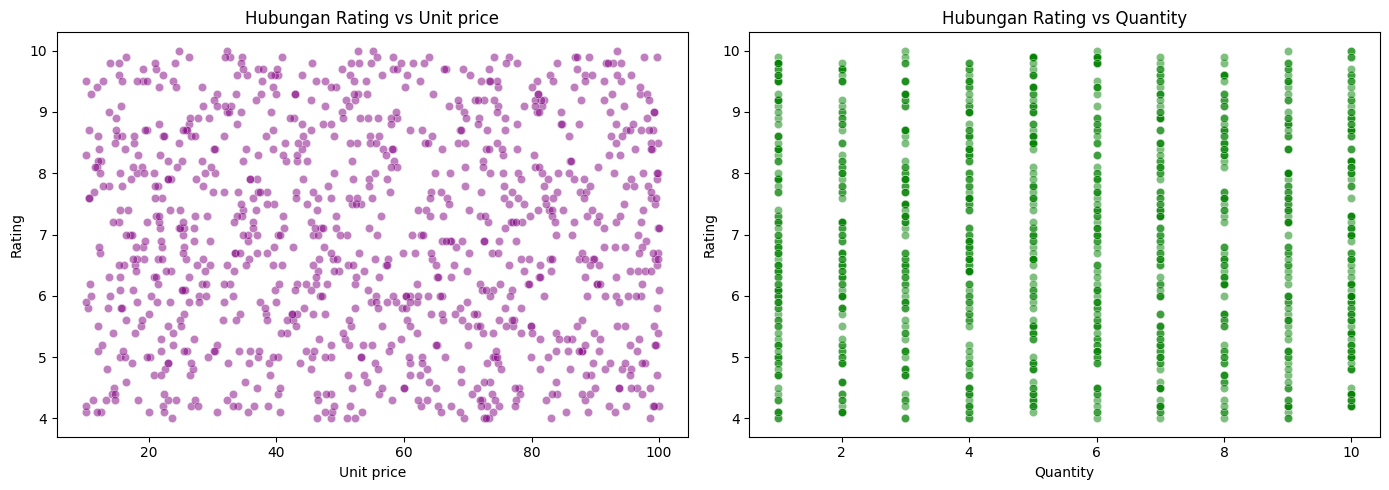

In [17]:
# 3. Membuat Diagram Sebar (Scatter Plot) antara Fitur Utama dan Target
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.scatterplot(x=df['Unit price'], y=df['Rating'], ax=axes[0], alpha=0.5, color='purple')
axes[0].set_title('Hubungan Rating vs Unit price')
axes[0].set_xlabel('Unit price')
axes[0].set_ylabel('Rating')

sns.scatterplot(x=df['Quantity'], y=df['Rating'], ax=axes[1], alpha=0.5, color='green')
axes[1].set_title('Hubungan Rating vs Quantity')
axes[1].set_xlabel('Quantity')
axes[1].set_ylabel('Rating')

plt.tight_layout()
plt.show()

**Kesimpulan Langkah 4**
1. Bentuk sebaran: berdasarkan hasil dari histogram sebaran rating memiliki nilai yang merata dari 4.0 - 10.0 tanpa kemencengan kuat ke satu sisi.
2. Target rating bersifat kontinu, namun rentangnya dibatasi dari 4.0 sampai 10.0 . Hal tersebut dapat mengakibatkan residu berpotensi membentuk pola  bertingkat, tidak menyebar acak
3. Nilai Muastahil  pada target: Dilihat dari histogram nilai terkecil 4.0 dan terbesar 10.0 tidak ada nilai 0 ataupun diatas dari 10. sehingga rating dinilai bersih dari nilai mustahil
4. Hubungan dengan calon fitur: hubungan korelasi antara target rating dengan fitur numerik yaitu unit price(-0,008) dan quantity(-0,015) berada sangat dekat dengan 0. sehingga tidak ada hubungan atau nilai hubungan yang sangat kecil antara fitur numerik dengan fitur target (rating). barang yang sangat harganya mahal dan yang murah bisa mendapatkan rating yang tinggi dan rendah secara acak
5. perkiraan dugaan awal: fitur yang diduga berpengaruh terhadap rating adalah fitur unit price dan dan product line. karena kebiasaannya rating sering dipengaruhi oleh nilai beli dan kategori produk. namun dari hasil eksplorasi matriks korelasi dan diagram sebaran, korelasi fitur dengan rating itu sangat kecil dan mendekati 0.

Langkah 5

In [18]:
# pemeriksaan cepat: fitur numerik yang terlalu akrab dengan target
kor = df.select_dtypes('float64', 'int64').corr(numeric_only=True)[target].drop(target).abs()
print('CURIGAI:', list(kor[kor > 0.95].index))

CURIGAI: []


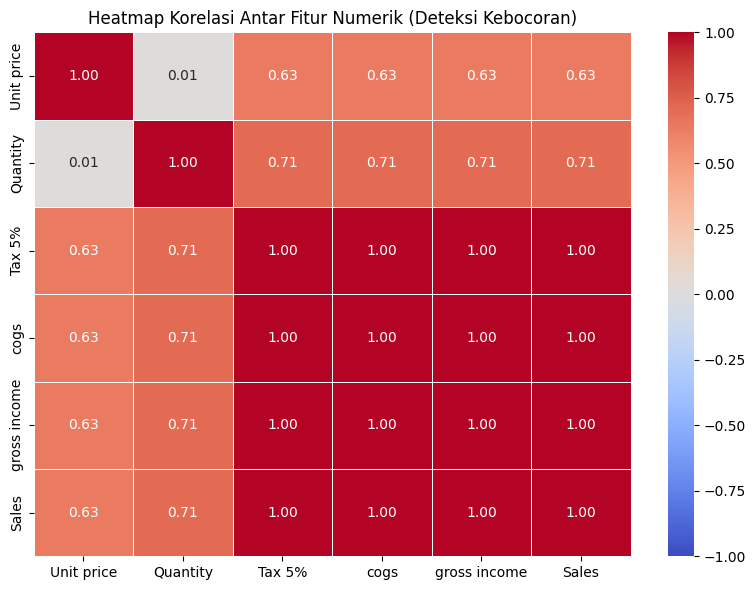

=== PEMBUKTIAN KEBOCORAN MATEMATIS ===
Apakah 'cogs' == 'Unit price' * 'Quantity'?: True
Apakah 'Tax 5%' == 'cogs' * 0.05?: False
Apakah 'gross income' == 'Tax 5%'?: True
Apakah 'Sales' == 'cogs' + 'Tax 5%'?: False


In [19]:
import seaborn as sns


# Memilih hanya kolom numerik sebagai calon fitur (tanpa target dan tanpa kolom konstan)
calon_fitur = ['Unit price', 'Quantity', 'Tax 5%', 'cogs', 'gross income', 'Sales']
df_fitur = df[calon_fitur]

# Menghitung matriks korelasi antar fitur
corr_matrix = df_fitur.corr()

# 1. Visualisasi Heatmap Multikolinearitas
plt.figure(figsize=(8, 6))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', vmin=-1, vmax=1, fmt=".2f", linewidths=0.5)
plt.title("Heatmap Korelasi Antar Fitur Numerik (Deteksi Kebocoran)")
plt.tight_layout()
plt.show()

# 2. Pembuktian Kebocoran Matematis (Data Leakage)
print("=== PEMBUKTIAN KEBOCORAN MATEMATIS ===")
print("Apakah 'cogs' == 'Unit price' * 'Quantity'?:",
      (round(df['cogs'], 2) == round(df['Unit price'] * df['Quantity'], 2)).all())
print("Apakah 'Tax 5%' == 'cogs' * 0.05?:",
      (round(df['Tax 5%'], 2) == round(df['cogs'] * 0.05, 2)).all())
print("Apakah 'gross income' == 'Tax 5%'?:",
      (round(df['gross income'], 2) == round(df['Tax 5%'], 2)).all())
print("Apakah 'Sales' == 'cogs' + 'Tax 5%'?:",
      (round(df['Sales'], 2) == round(df['cogs'] + df['Tax 5%'], 2)).all())

In [20]:
print(pd.crosstab(df['Branch'], df['City']))

City    Mandalay  Naypyitaw  Yangon
Branch                             
Alex           0          0     340
Cairo        332          0       0
Giza           0        328       0


**Langkah 6: Visualisasi**

In [21]:
import matplotlib.pyplot as plt
import seaborn as sns

# Ubah tipe agar jam transaksi bisa dipakai (temuan Langkah 2)
df['Date'] = pd.to_datetime(df['Date'], format='%m/%d/%Y')
df['Jam']  = pd.to_datetime(df['Time'], format='%I:%M:%S %p').dt.hour

1. Histogram

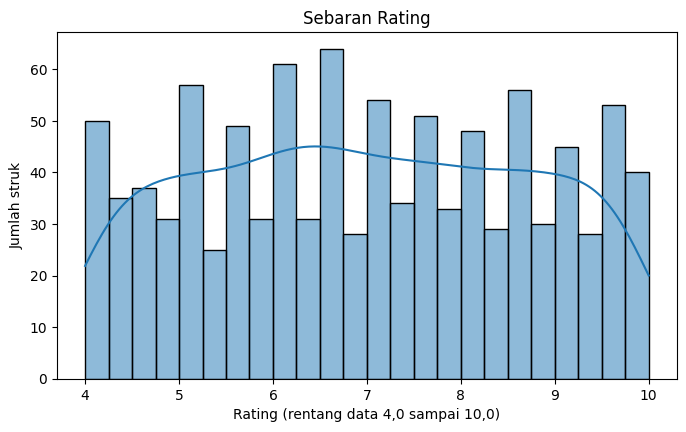

kemencengan: 0.009


In [25]:
fig, ax = plt.subplots(figsize=(8, 4.5))
sns.histplot(df['Rating'], bins=24, kde=True, ax=ax)
ax.set_title('Sebaran Rating')
ax.set_xlabel('Rating (rentang data 4,0 sampai 10,0)')
ax.set_ylabel('Jumlah struk')
plt.show()
print('kemencengan:', round(df['Rating'].skew(), 3))

pada visualisasi histogram menunjukan kemencengan 0.009 yang berari memiliki sebaran yang merata dari rentang 4,0 -  10,0.

2. Diagram kotak

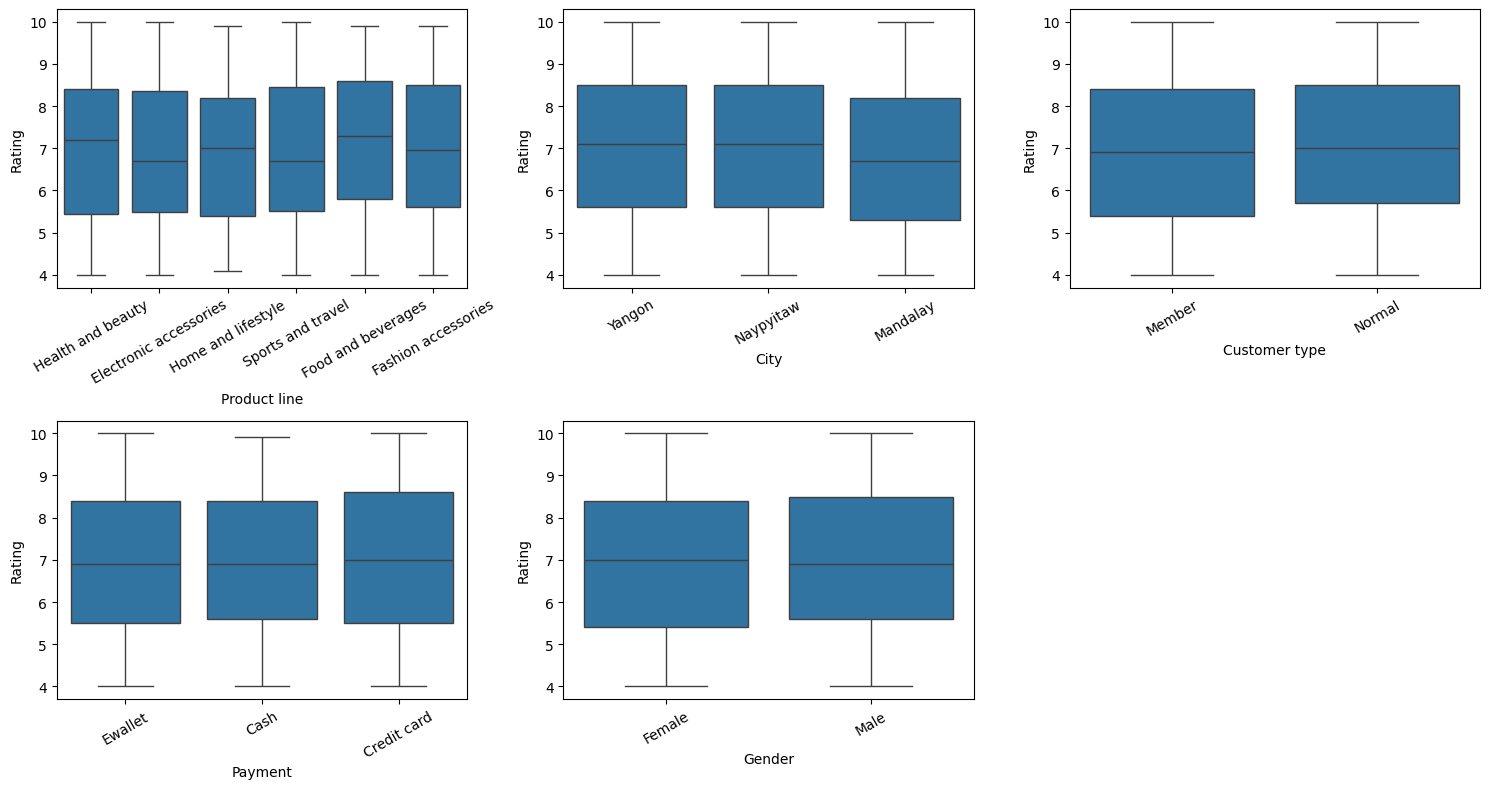

Product line {'Electronic accessories': 6.92, 'Fashion accessories': 7.03, 'Food and beverages': 7.11, 'Health and beauty': 7.0, 'Home and lifestyle': 6.84, 'Sports and travel': 6.92}
City {'Mandalay': 6.82, 'Naypyitaw': 7.07, 'Yangon': 7.03}
Customer type {'Member': 6.92, 'Normal': 7.04}
Payment {'Cash': 6.97, 'Credit card': 7.0, 'Ewallet': 6.95}
Gender {'Female': 6.96, 'Male': 6.99}


In [26]:
kategori = ['Product line', 'City', 'Customer type', 'Payment', 'Gender']
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, k in zip(axes.ravel(), kategori):
    sns.boxplot(data=df, x=k, y='Rating', ax=ax)
    ax.tick_params(axis='x', rotation=30)
axes.ravel()[-1].axis('off')
fig.tight_layout(); plt.show()

for k in kategori:
    print(k, df.groupby(k)['Rating'].mean().round(2).to_dict())

3. Diagram Sebar

In [30]:
target = 'Rating'
num_cols = df.select_dtypes(include=['float64', 'int64'])
print("=== KORELASI FITUR NUMERIK TERHADAP RATING ===")
print(num_cols.corr()[target].sort_values(ascending=False))



=== KORELASI FITUR NUMERIK TERHADAP RATING ===
Rating                     1.000000
Unit price                -0.008778
Quantity                  -0.015815
cogs                      -0.036442
Tax 5%                    -0.036442
gross income              -0.036442
Sales                     -0.036442
gross margin percentage         NaN
Name: Rating, dtype: float64


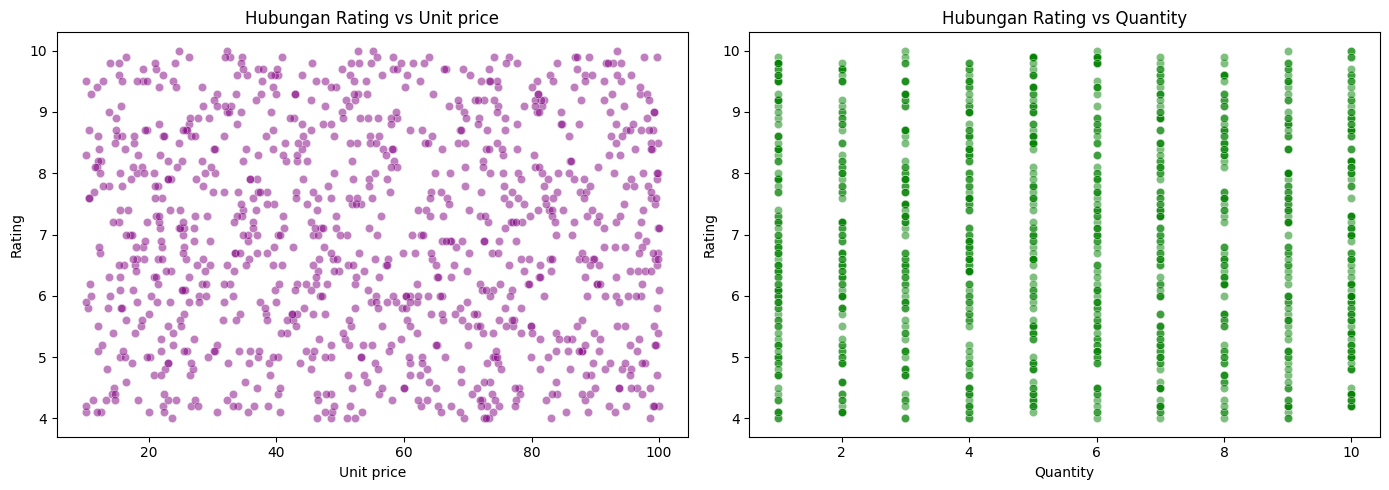

In [31]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.scatterplot(x=df['Unit price'], y=df['Rating'], ax=axes[0], alpha=0.5, color='purple')
axes[0].set_title('Hubungan Rating vs Unit price')
axes[0].set_xlabel('Unit price')
axes[0].set_ylabel('Rating')

sns.scatterplot(x=df['Quantity'], y=df['Rating'], ax=axes[1], alpha=0.5, color='green')
axes[1].set_title('Hubungan Rating vs Quantity')
axes[1].set_xlabel('Quantity')
axes[1].set_ylabel('Rating')

plt.tight_layout()
plt.show()

4.

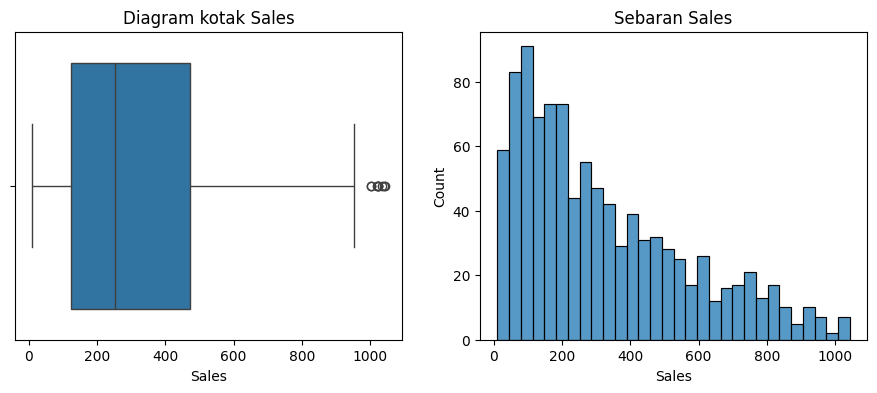

Unit price: pagar [-34.7, 145.5] | di luar pagar: 0 | min 10.08 | maks 99.96
Quantity: pagar [-4.5, 15.5] | di luar pagar: 0 | min 1 | maks 10
Sales: pagar [-396.0, 991.7] | di luar pagar: 9 | min 10.6785 | maks 1042.65


In [42]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.boxplot(x=df['Sales'], ax=axes[0]); axes[0].set_title('Diagram kotak Sales')
sns.histplot(df['Sales'], bins=30, ax=axes[1]); axes[1].set_title('Sebaran Sales')
plt.show()

for k in ['Unit price', 'Quantity', 'Sales']:
    q1, q3 = df[k].quantile([.25, .75])
    iqr = q3 - q1
    bawah, atas = q1 - 1.5*iqr, q3 + 1.5*iqr
    n = ((df[k] < bawah) | (df[k] > atas)).sum()
    print(f'{k}: pagar [{bawah:.1f}, {atas:.1f}] | di luar pagar: {n} | min {df[k].min()} | maks {df[k].max()}')


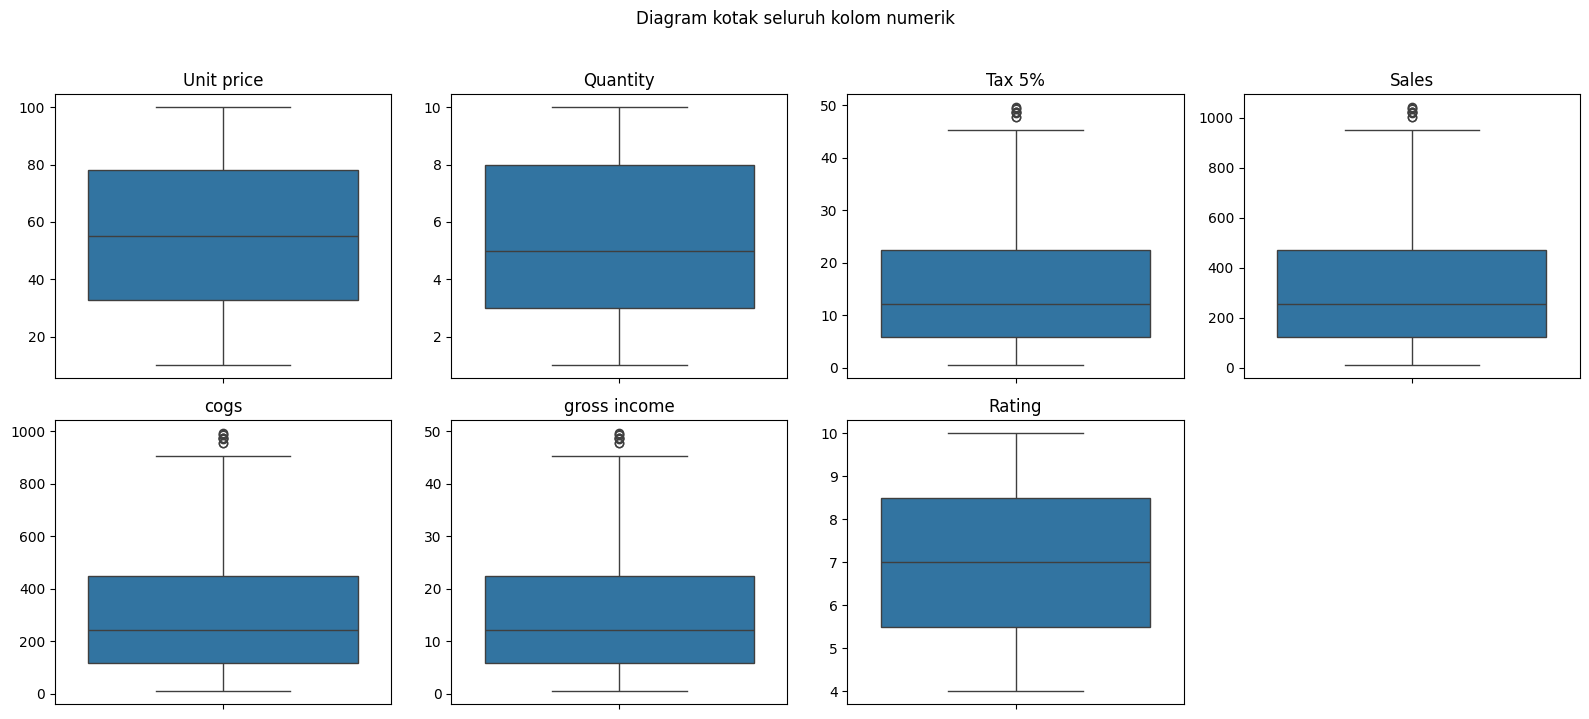

       kolom  pagar_bawah  pagar_atas  jumlah_di_luar     min    maks
  Unit price       -34.72      145.53               0 10.0800   99.96
    Quantity        -4.50       15.50               0  1.0000   10.00
      Tax 5%       -18.86       47.23               9  0.5085   49.65
       Sales      -395.97      991.74               9 10.6785 1042.65
        cogs      -377.11      944.52               9 10.1700  993.00
gross income       -18.86       47.23               9  0.5085   49.65
      Rating         1.00       13.00               0  4.0000   10.00


In [43]:
# Kolom numerik; gross margin percentage dikecualikan karena konstan (kotaknya hanya garis)
num = df.select_dtypes(include=['float64', 'int64']).columns.drop('gross margin percentage')

# 1) Diagram kotak semua kolom numerik
n = len(num)
kolom_grid = 4
baris_grid = -(-n // kolom_grid)          # pembulatan ke atas
fig, axes = plt.subplots(baris_grid, kolom_grid, figsize=(16, 3.5 * baris_grid))
axes = axes.ravel()
for ax, k in zip(axes, num):
    sns.boxplot(y=df[k], ax=ax)
    ax.set_title(k); ax.set_ylabel('')
for ax in axes[n:]:
    ax.axis('off')
fig.suptitle('Diagram kotak seluruh kolom numerik', y=1.02)
fig.tight_layout(); plt.show()

# 2) Tabel pencilan per kolom (aturan pagar 1,5 × IQR)
hasil = []
for k in num:
    q1, q3 = df[k].quantile([.25, .75])
    iqr = q3 - q1
    bawah, atas = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    luar = ((df[k] < bawah) | (df[k] > atas)).sum()
    hasil.append([k, round(bawah, 2), round(atas, 2), luar, df[k].min(), df[k].max()])

tabel_pencilan = pd.DataFrame(hasil, columns=['kolom', 'pagar_bawah', 'pagar_atas',
                                              'jumlah_di_luar', 'min', 'maks'])
print(tabel_pencilan.to_string(index=False))

5.

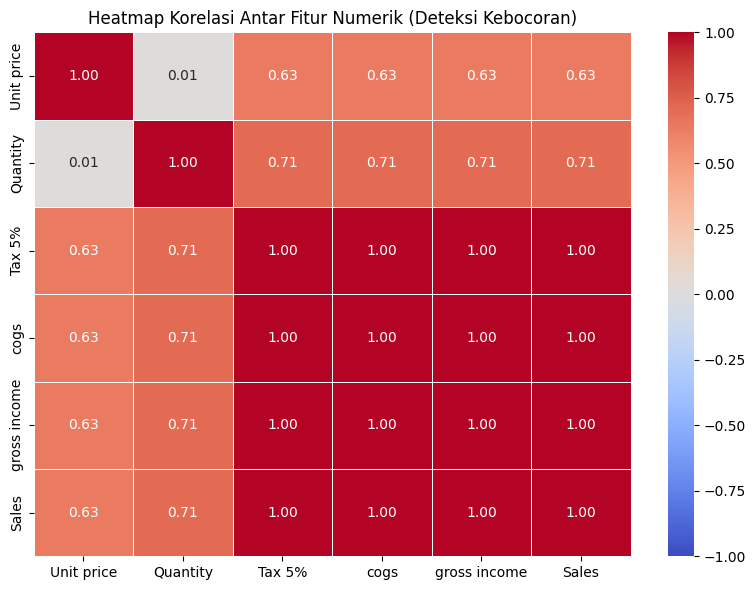

In [33]:
# Memilih hanya kolom numerik sebagai calon fitur (tanpa target dan tanpa kolom konstan)
calon_fitur = ['Unit price', 'Quantity', 'Tax 5%', 'cogs', 'gross income', 'Sales']
df_fitur = df[calon_fitur]

# Menghitung matriks korelasi antar fitur
corr_matrix = df_fitur.corr()

# 1. Visualisasi Heatmap Multikolinearitas
plt.figure(figsize=(8, 6))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', vmin=-1, vmax=1, fmt=".2f", linewidths=0.5)
plt.title("Heatmap Korelasi Antar Fitur Numerik (Deteksi Kebocoran)")
plt.tight_layout()
plt.show()

6.

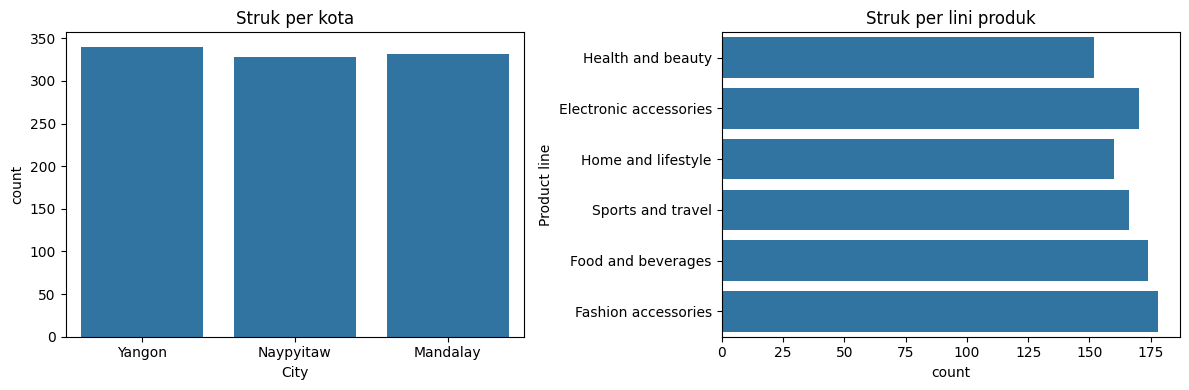

Product line  Electronic accessories  Fashion accessories  Food and beverages  \
City                                                                            
Mandalay                          55                   62                  50   
Naypyitaw                         55                   65                  66   
Yangon                            60                   51                  58   

Product line  Health and beauty  Home and lifestyle  Sports and travel  
City                                                                    
Mandalay                     53                  50                 62  
Naypyitaw                    52                  45                 45  
Yangon                       47                  65                 59  


In [34]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.countplot(data=df, x='City', ax=axes[0]); axes[0].set_title('Struk per kota')
sns.countplot(data=df, y='Product line', ax=axes[1]); axes[1].set_title('Struk per lini produk')
plt.tight_layout(); plt.show()

print(pd.crosstab(df['City'], df['Product line']))